In [1]:

# Check Python environment and available storage

import os
import sys

print("Python version:", sys.version)
print("Current working directory:", os.getcwd())

# Check available disk space
disk = os.statvfs("/content")
free_space_gb = (disk.f_bavail * disk.f_frsize) / (1024 ** 3)

print(f"Available disk space: {free_space_gb:.2f} GB")


Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Current working directory: /content
Available disk space: 107.62 GB


In [2]:

# Install dataset preparation libraries

!pip install -q datasets huggingface_hub pandas pillow tqdm

print("Required libraries installed successfully.")


Required libraries installed successfully.


In [3]:

from pathlib import Path

# Define dataset directories
BASE_DIR = Path("/content/data/vision/test_images")

DIRECTORIES = [
    BASE_DIR / "single_food",
    BASE_DIR / "multiple_foods",
    BASE_DIR / "mixed_dishes",
    BASE_DIR / "annotations"
]

# Create directories
for directory in DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)

print("Dataset directory structure created successfully.")

for directory in DIRECTORIES:
    print(directory)


Dataset directory structure created successfully.
/content/data/vision/test_images/single_food
/content/data/vision/test_images/multiple_foods
/content/data/vision/test_images/mixed_dishes
/content/data/vision/test_images/annotations


In [4]:

import pandas as pd

# Define annotation columns
columns = [
    "image_id",
    "file_name",
    "food_items",
    "scenario",
    "source",
    "license"
]

# Create an empty annotations file
annotations = pd.DataFrame(columns=columns)

ANNOTATIONS_FILE = BASE_DIR / "annotations" / "annotations.csv"
annotations.to_csv(ANNOTATIONS_FILE, index=False)

print("Annotations file created:", ANNOTATIONS_FILE)
print(annotations)


Annotations file created: /content/data/vision/test_images/annotations/annotations.csv
Empty DataFrame
Columns: [image_id, file_name, food_items, scenario, source, license]
Index: []


In [5]:

import requests

# Official Fruits-360 repository
API_URL = "https://api.github.com/repos/fruits-360/fruits-360-100x100/contents/Training"

response = requests.get(API_URL)
response.raise_for_status()

dataset_classes = [
    item["name"]
    for item in response.json()
    if item["type"] == "dir"
]

# Foods from our Kora AI catalog
food_catalog = [
    "apple", "banana", "orange", "strawberry",
    "grape", "pear", "peach", "kiwi",
    "mango", "pineapple", "watermelon",
    "lemon", "lime", "avocado", "tomato",
    "carrot", "cucumber", "onion", "garlic",
    "potato", "corn", "bell pepper"
]

# Find matching categories
matching_classes = []

for food in food_catalog:
    matches = [
        category for category in dataset_classes
        if food.lower() in category.lower()
    ]
    matching_classes.extend(matches)

matching_classes = sorted(set(matching_classes))

print("Available matching categories:")
for category in matching_classes:
    print("-", category)

print("\nTotal matching categories:", len(matching_classes))


Available matching categories:
- Apple 10
- Apple 11
- Apple 12
- Apple 13
- Apple 14
- Apple 17
- Apple 18
- Apple 19
- Apple 20
- Apple 21
- Apple 22
- Apple 23
- Apple 5
- Apple 6
- Apple 7
- Apple 8
- Apple 9
- Apple Braeburn 1
- Apple Crimson Snow 1
- Apple Golden 1
- Apple Golden 2
- Apple Golden 3
- Apple Granny Smith 1
- Apple Pink Lady 1
- Apple Red 1
- Apple Red 2
- Apple Red 3
- Apple Red Delicious 1
- Apple Red Yellow 1
- Apple Red Yellow 2
- Avocado 1
- Avocado 2
- Avocado Black 1
- Avocado Black 2
- Avocado Green 1
- Banana 1
- Banana 2
- Banana 3
- Banana 4
- Banana Lady Finger 1
- Banana Red 1
- Carrot 1
- Corn 1
- Corn Husk 1
- Cucumber 1
- Cucumber 10
- Cucumber 11
- Cucumber 12
- Cucumber 13
- Cucumber 3
- Cucumber 4
- Cucumber 5
- Cucumber 6
- Cucumber 7
- Cucumber 8
- Cucumber 9
- Grape 1
- Grape Blue 1
- Grape Pink 1
- Grape White 1
- Grape White 2
- Grape White 3
- Grape White 4
- Grape pink 2
- Grapefruit Pink 1
- Grapefruit White 1
- Kiwi 1
- Kiwi 2
- Kiwi 3
- 

In [6]:

import requests
import re

# Get the official test categories
TEST_API_URL = (
    "https://api.github.com/repos/fruits-360/"
    "fruits-360-100x100/contents/Test"
)

response = requests.get(TEST_API_URL)
response.raise_for_status()

test_classes = [
    item["name"]
    for item in response.json()
    if item["type"] == "dir"
]

# Map dataset categories to Kora AI food labels
category_mapping = {
    "apple": r"^apple(?:\s|$)",
    "avocado": r"^avocado(?:\s|$)",
    "banana": r"^banana(?:\s|$)",
    "carrot": r"^carrot(?:\s|$)",
    "corn": r"^corn(?:\s|$)",
    "cucumber": r"^cucumber(?:\s|$)",
    "grape": r"^grape(?:\s|$)",
    "kiwi": r"^kiwi(?:\s|$)",
    "lemon": r"^lemon(?:\s|$)",
    "lime": r"^limes?(?:\s|$)",
    "mango": r"^mango(?:\s|$)",
    "onion": r"^onion(?:\s|$)",
    "orange": r"^orange(?:\s|$)",
    "peach": r"^peach(?:\s|$)",
    "pear": r"^pear(?:\s|$)",
    "bell pepper": r"^pepper\s+orange(?:\s|$)",
    "pineapple": r"^pineapple(?:\s|$)",
    "potato": r"^potato\s+(?:red|white)(?:\s|$)",
    "strawberry": r"^strawberry(?:\s|$)",
    "tomato": r"^tomato(?:\s|$)",
    "watermelon": r"^watermelon(?:\s|$)",
    "garlic": r"^garlic(?:\s|$)"
}

# Normalize categories
normalized_categories = {}

for category in test_classes:
    for food, pattern in category_mapping.items():
        if re.search(pattern, category, re.IGNORECASE):
            normalized_categories.setdefault(food, []).append(category)
            break

print("Normalized foods available in Test:\n")

for food, categories in sorted(normalized_categories.items()):
    print(f"{food}: {len(categories)} categories")

print("\nTotal foods:", len(normalized_categories))
print("Total dataset categories:", sum(
    len(categories) for categories in normalized_categories.values()
))


Normalized foods available in Test:

apple: 30 categories
avocado: 5 categories
banana: 6 categories
bell pepper: 2 categories
carrot: 1 categories
corn: 2 categories
cucumber: 12 categories
garlic: 1 categories
grape: 9 categories
kiwi: 3 categories
lemon: 2 categories
lime: 1 categories
mango: 2 categories
onion: 6 categories
orange: 6 categories
peach: 7 categories
pear: 20 categories
pineapple: 2 categories
potato: 3 categories
strawberry: 4 categories
tomato: 19 categories
watermelon: 1 categories

Total foods: 22
Total dataset categories: 144


In [8]:

import subprocess
import shutil
import random
import pandas as pd
from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from urllib.parse import quote

# Repository configuration
REPO_DIR = Path("/content/fruits360_repo")
REPO_URL = (
    "https://github.com/fruits-360/"
    "fruits-360-100x100.git"
)

# Remove previous incomplete repository, if any
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)

# Clone repository without downloading all image files
print("Connecting to Fruits-360 repository...")

subprocess.run(
    [
        "git", "clone",
        "--depth", "1",
        "--filter=blob:none",
        "--sparse",
        REPO_URL,
        str(REPO_DIR)
    ],
    check=True
)

# Download only the required test categories
sparse_paths = [
    f"Test/{category}"
    for categories in normalized_categories.values()
    for category in categories
]

print("Preparing selected image categories...")

subprocess.run(
    [
        "git", "sparse-checkout", "set",
        "--cone",
        *sparse_paths
    ],
    cwd=REPO_DIR,
    check=True
)

# Remove images from the previous incomplete attempt
for old_image in (BASE_DIR / "single_food").glob("IMG_*"):
    old_image.unlink()

# Select and download images
random.seed(42)
annotations_data = []
image_counter = 1

for food, categories in sorted(normalized_categories.items()):

    candidates = []

    for category in categories:
        category_dir = REPO_DIR / "Test" / category

        if not category_dir.exists():
            continue

        for file_path in category_dir.iterdir():
            if file_path.suffix.lower() in (
                ".jpg", ".jpeg", ".png"
            ):
                candidates.append((category, file_path))

    random.shuffle(candidates)
    selected_images = candidates[:10]

    for category, file_path in tqdm(
        selected_images,
        desc=f"Downloading {food}",
        leave=False
    ):
        try:
            image_name = f"IMG_{image_counter:03d}.jpg"
            image_path = BASE_DIR / "single_food" / image_name

            with Image.open(file_path) as image:
                image.convert("RGB").save(
                    image_path,
                    format="JPEG",
                    quality=95
                )

            source_url = (
                "https://github.com/fruits-360/"
                "fruits-360-100x100/blob/main/Test/"
                f"{quote(category)}/{quote(file_path.name)}"
            )

            annotations_data.append({
                "image_id": f"IMG_{image_counter:03d}",
                "file_name": image_name,
                "food_items": food,
                "scenario": "single_food",
                "source": source_url,
                "license": "See dataset repository license"
            })

            image_counter += 1

        except Exception as error:
            print(f"Error processing {file_path}: {error}")

# Save annotations
annotations = pd.DataFrame(annotations_data)

annotations.to_csv(
    ANNOTATIONS_FILE,
    index=False
)

print("\nDownload completed!")
print("Images downloaded:", len(annotations))
print("Foods represented:", annotations["food_items"].nunique())
print("Annotations saved:", ANNOTATIONS_FILE)


Connecting to Fruits-360 repository...
Preparing selected image categories...



Download completed!
Images downloaded: 220
Foods represented: 22
Annotations saved: /content/data/vision/test_images/annotations/annotations.csv


In [9]:

from PIL import Image
from collections import Counter
import hashlib

# Load annotations
annotations = pd.read_csv(ANNOTATIONS_FILE)

valid_images = []
invalid_images = []
image_hashes = {}

for _, row in annotations.iterrows():
    image_path = BASE_DIR / "single_food" / row["file_name"]

    try:
        with Image.open(image_path) as image:
            image.verify()

        # Detect duplicate image content
        image_hash = hashlib.md5(
            image_path.read_bytes()
        ).hexdigest()

        image_hashes.setdefault(image_hash, []).append(
            row["file_name"]
        )

        valid_images.append(row["file_name"])

    except Exception as error:
        invalid_images.append({
            "file": row["file_name"],
            "error": str(error)
        })

duplicates = {
    key: files
    for key, files in image_hashes.items()
    if len(files) > 1
}

print("DATASET VALIDATION")
print("------------------")
print("CSV records:", len(annotations))
print("Valid images:", len(valid_images))
print("Invalid images:", len(invalid_images))
print("Duplicate groups:", len(duplicates))

print("\nImages per food:")
print(annotations["food_items"].value_counts().sort_index())

print("\nValidation completed.")


DATASET VALIDATION
------------------
CSV records: 220
Valid images: 220
Invalid images: 0
Duplicate groups: 0

Images per food:
food_items
apple          10
avocado        10
banana         10
bell pepper    10
carrot         10
corn           10
cucumber       10
garlic         10
grape          10
kiwi           10
lemon          10
lime           10
mango          10
onion          10
orange         10
peach          10
pear           10
pineapple      10
potato         10
strawberry     10
tomato         10
watermelon     10
Name: count, dtype: int64

Validation completed.


In [10]:

from google.colab import drive
import shutil
from pathlib import Path

# Mount Google Drive to preserve the generated dataset
drive.mount("/content/drive")

# Define the backup destination
DRIVE_DIR = Path(
    "/content/drive/MyDrive/KoraAI/vision/test_images"
)

# Create the destination directory
DRIVE_DIR.parent.mkdir(parents=True, exist_ok=True)

# Copy the dataset to Google Drive
if DRIVE_DIR.exists():
    shutil.rmtree(DRIVE_DIR)

shutil.copytree(BASE_DIR, DRIVE_DIR)

print("Dataset backup completed successfully!")
print("Backup location:", DRIVE_DIR)


Mounted at /content/drive
Dataset backup completed successfully!
Backup location: /content/drive/MyDrive/KoraAI/vision/test_images


In [11]:

# Verify the backed-up dataset files

backup_images = list(
    (DRIVE_DIR / "single_food").glob("*.jpg")
)

backup_csv = DRIVE_DIR / "annotations" / "annotations.csv"

print("BACKUP VALIDATION")
print("-----------------")
print("Backed-up images:", len(backup_images))
print("Annotations file exists:", backup_csv.exists())

if backup_csv.exists():
    backup_annotations = pd.read_csv(backup_csv)
    print("Annotation records:", len(backup_annotations))

assert len(backup_images) == 220
assert backup_csv.exists()
assert len(backup_annotations) == 220

print("\nBackup verified successfully!")


BACKUP VALIDATION
-----------------
Backed-up images: 220
Annotations file exists: True
Annotation records: 220

Backup verified successfully!


In [12]:

from datasets import load_dataset

# Load the validation split of FoodSeg103
print("Loading FoodSeg103 validation split...")

foodseg_dataset = load_dataset(
    "Tubisi/FoodSeg103",
    split="validation"
)

# Display basic dataset information
print("\nDATASET INFORMATION")
print("-------------------")
print("Total images:", len(foodseg_dataset))
print("Available columns:", foodseg_dataset.column_names)
print("Dataset features:", foodseg_dataset.features)

# Inspect the first sample
sample = foodseg_dataset[0]

print("\nFIRST SAMPLE")
print("------------")
print("Image size:", sample["image"].size)
print("Food category IDs:", sample["classes_on_image"])
print("Sample ID:", sample["id"])


Loading FoodSeg103 validation split...


README.md:   0%|          | 0.00/6.71k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  351MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

... (3 outputs left out)

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4983 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2135 [00:00<?, ? examples/s]


DATASET INFORMATION
-------------------
Total images: 2135
Available columns: ['image', 'label', 'classes_on_image', 'id']
Dataset features: {'image': Image(mode=None, decode=True), 'label': Image(mode=None, decode=True), 'classes_on_image': List(Value('int64')), 'id': Value('int64')}

FIRST SAMPLE
------------
Image size: (512, 485)
Food category IDs: [0, 20, 56, 66, 84, 96]
Sample ID: 0


In [13]:

# Define the official FoodSeg103 category mapping
foodseg_classes = [
    "background",
    "candy",
    "egg tart",
    "french fries",
    "chocolate",
    "biscuit",
    "popcorn",
    "pudding",
    "ice cream",
    "cheese butter",
    "cake",
    "wine",
    "milkshake",
    "coffee",
    "juice",
    "milk",
    "tea",
    "almond",
    "red beans",
    "cashew",
    "dried cranberries",
    "soy",
    "walnut",
    "peanut",
    "egg",
    "apple",
    "date",
    "apricot",
    "avocado",
    "banana",
    "strawberry",
    "cherry",
    "blueberry",
    "raspberry",
    "mango",
    "olives",
    "peach",
    "lemon",
    "pear",
    "fig",
    "pineapple",
    "grape",
    "kiwi",
    "melon",
    "orange",
    "watermelon",
    "steak",
    "pork",
    "chicken duck",
    "sausage",
    "fried meat",
    "lamb",
    "sauce",
    "crab",
    "fish",
    "shellfish",
    "shrimp",
    "soup",
    "bread",
    "corn",
    "hamburg",
    "pizza",
    "hanamaki baozi",
    "wonton dumplings",
    "pasta",
    "noodles",
    "rice",
    "pie",
    "tofu",
    "eggplant",
    "potato",
    "garlic",
    "cauliflower",
    "tomato",
    "kelp",
    "seaweed",
    "spring onion",
    "rape",
    "ginger",
    "okra",
    "lettuce",
    "pumpkin",
    "cucumber",
    "white radish",
    "carrot",
    "asparagus",
    "bamboo shoots",
    "broccoli",
    "celery stick",
    "cilantro mint",
    "snow peas",
    "cabbage",
    "bean sprouts",
    "onion",
    "pepper",
    "green beans",
    "french beans",
    "king oyster mushroom",
    "shiitake",
    "enoki mushroom",
    "oyster mushroom",
    "white button mushroom",
    "salad",
    "other ingredients"
]

# Create an ID-to-name dictionary
foodseg_class_mapping = {
    class_id: class_name
    for class_id, class_name in enumerate(foodseg_classes)
}

# Display the categories present in the first sample
sample = foodseg_dataset[0]

print("FIRST SAMPLE CATEGORIES")
print("-----------------------")

for class_id in sample["classes_on_image"]:
    class_name = foodseg_class_mapping.get(
        class_id, "unknown"
    )
    print(f"ID {class_id}: {class_name}")

print("\nTotal categories:", len(foodseg_class_mapping))


FIRST SAMPLE CATEGORIES
-----------------------
ID 0: background
ID 20: dried cranberries
ID 56: shrimp
ID 66: rice
ID 84: carrot
ID 96: french beans

Total categories: 104


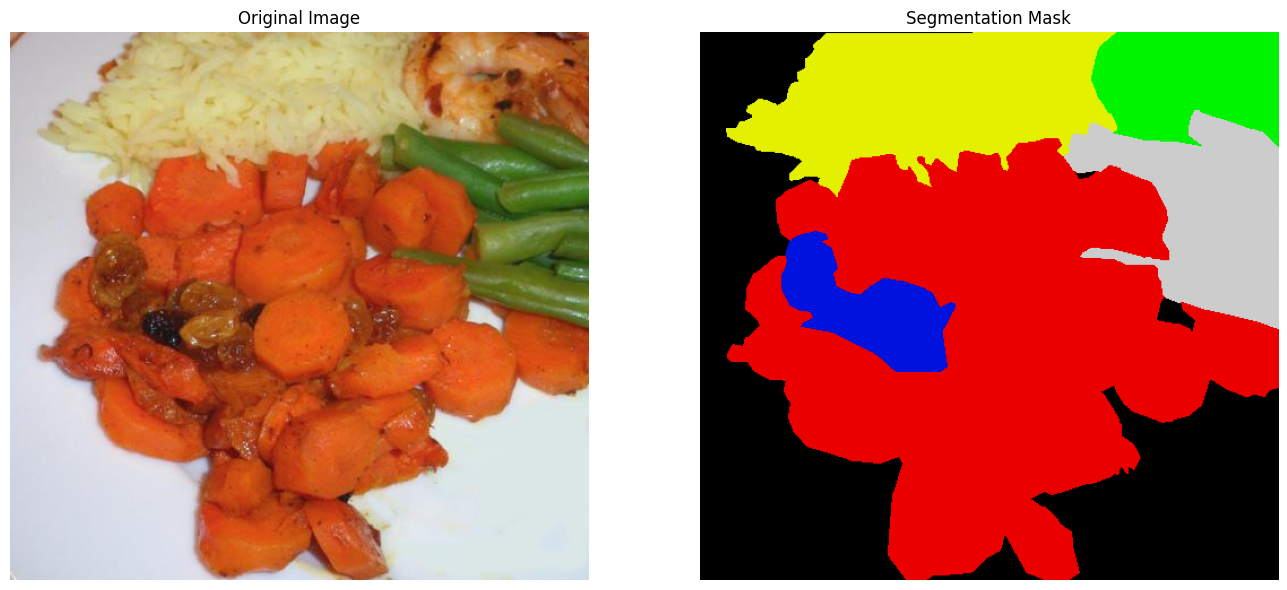

Mask category IDs: [ 0 20 56 66 84 96]
Annotated categories: [0, 20, 56, 66, 84, 96]


In [14]:

import matplotlib.pyplot as plt
import numpy as np

# Retrieve one sample image and its segmentation mask
sample = foodseg_dataset[0]

original_image = sample["image"]
segmentation_mask = np.array(sample["label"])

# Display the original image and its segmentation mask
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(segmentation_mask, cmap="nipy_spectral")
axes[1].set_title("Segmentation Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Display the category IDs found in the mask
print("Mask category IDs:", np.unique(segmentation_mask))
print("Annotated categories:", sample["classes_on_image"])


In [15]:
# Identify FoodSeg103 images containing multiple catalog foods

# Define FoodSeg103 categories that match our food catalog
catalog_foods = {
    "apple", "avocado", "banana", "strawberry", "mango",
    "peach", "lemon", "pear", "pineapple", "grape",
    "kiwi", "orange", "watermelon", "egg", "steak",
    "pork", "chicken duck", "sausage", "fish", "shrimp",
    "bread", "corn", "rice", "tofu", "eggplant",
    "potato", "garlic", "tomato", "ginger", "lettuce",
    "cucumber", "carrot", "broccoli", "cabbage",
    "onion", "green beans", "french beans",
    "shiitake", "enoki mushroom", "oyster mushroom",
    "white button mushroom", "peanut", "almond",
    "cashew", "walnut"
}

# Find images containing at least two matching food categories
multi_food_samples = []

for index, sample in enumerate(foodseg_dataset):

    # Convert category IDs into category names
    category_names = [
        foodseg_class_mapping[class_id]
        for class_id in sample["classes_on_image"]
        if class_id != 0
    ]

    # Keep only categories included in our catalog
    matching_foods = [
        name for name in category_names
        if name in catalog_foods
    ]

    # Save samples with at least two matching foods
    if len(set(matching_foods)) >= 2:
        multi_food_samples.append({
            "index": index,
            "sample_id": sample["id"],
            "food_items": matching_foods
        })

# Display the results
print("MULTIPLE-FOOD IMAGE ANALYSIS")
print("----------------------------")
print("Total validation images:", len(foodseg_dataset))
print("Images with at least two catalog foods:", len(multi_food_samples))

print("\nFIRST 10 MATCHING SAMPLES")

for sample in multi_food_samples[:10]:
    print(
        f"Image {sample['sample_id']}: "
        f"{', '.join(sample['food_items'])}"
    )

MULTIPLE-FOOD IMAGE ANALYSIS
----------------------------
Total validation images: 2135
Images with at least two catalog foods: 1466

FIRST 10 MATCHING SAMPLES
Image 0: shrimp, rice, carrot, french beans
Image 1: shrimp, carrot, green beans
Image 2: pineapple, bread, tomato
Image 3: banana, grape
Image 4: fish, bread
Image 5: chicken duck, rice
Image 6: apple, grape, bread
Image 7: banana, strawberry, kiwi, bread
Image 8: chicken duck, carrot
Image 9: steak, cucumber, onion, shiitake


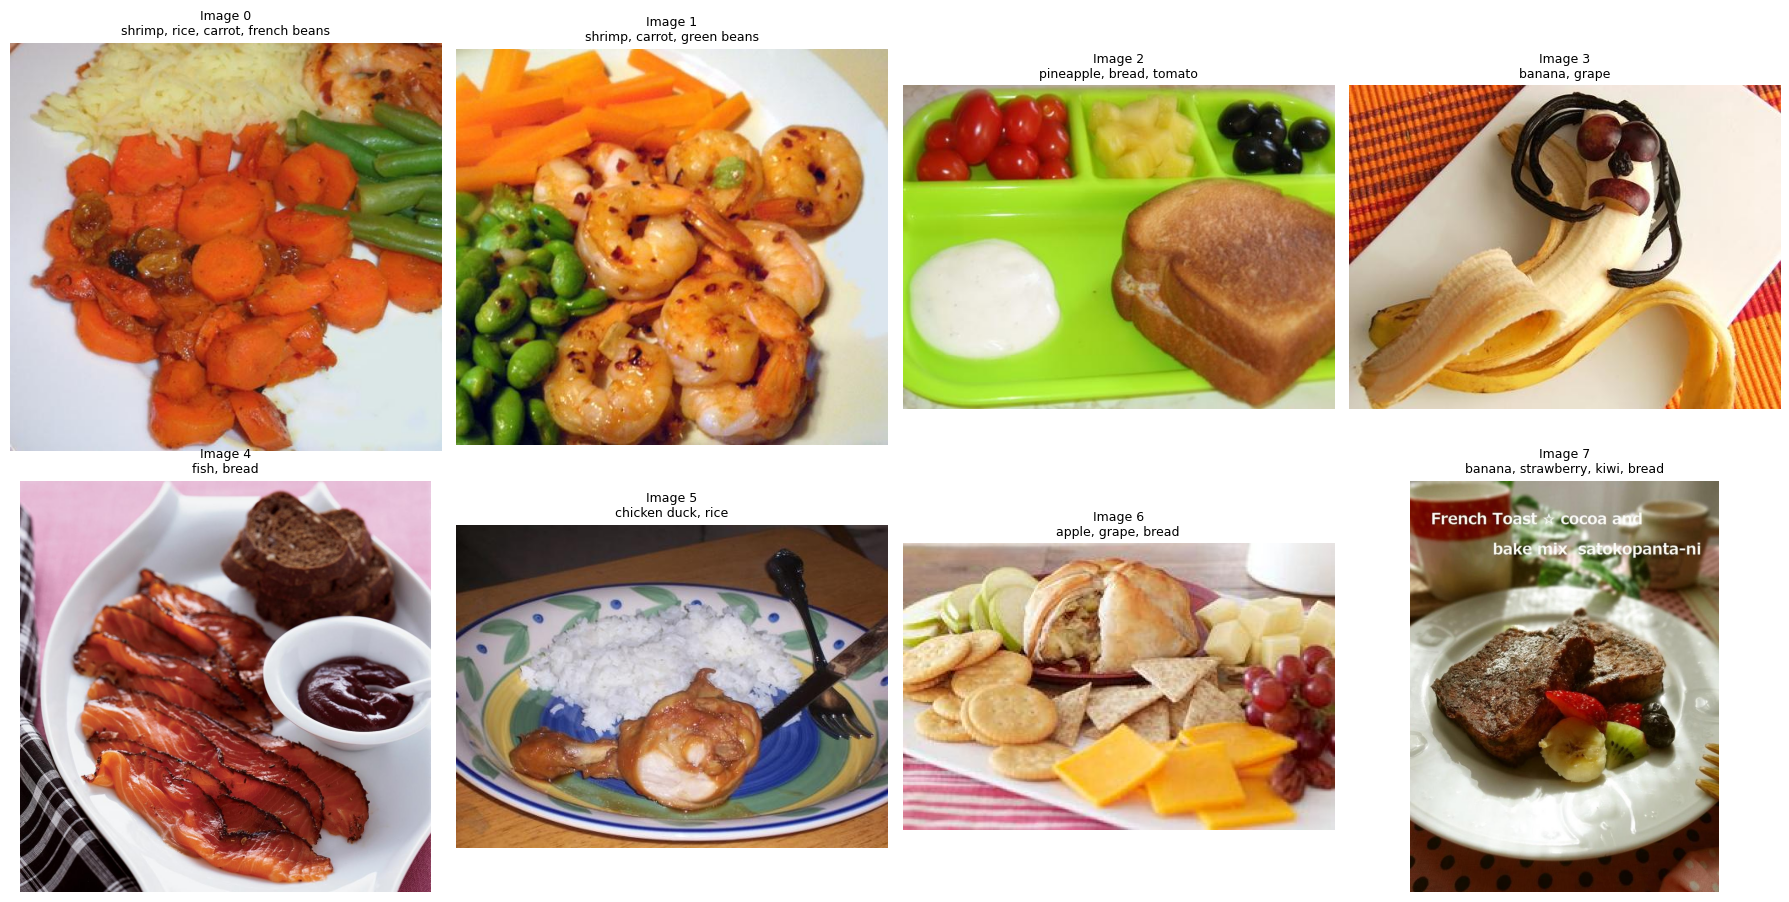

In [16]:
import matplotlib.pyplot as plt

# Select the first eight candidate samples
samples_to_display = multi_food_samples[:8]

# Create a visualization grid
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for axis, candidate in zip(axes, samples_to_display):

    # Retrieve the original dataset sample
    sample = foodseg_dataset[candidate["index"]]

    # Display the image
    axis.imshow(sample["image"])

    # Add image ID and food categories
    axis.set_title(
        f"Image {candidate['sample_id']}\n"
        f"{', '.join(candidate['food_items'])}",
        fontsize=9
    )

    axis.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Select 40 images while prioritizing food category diversity

# Define the target number of images
TARGET_IMAGES = 40

# Store the selected samples and category frequencies
selected_multi_foods = []
category_frequency = {}

# Keep track of candidates that have not been selected
remaining_candidates = multi_food_samples.copy()

# Select images iteratively
while len(selected_multi_foods) < TARGET_IMAGES:

    best_candidate = None
    best_score = -1

    for candidate in remaining_candidates:

        # Get unique food categories in the candidate
        foods = set(candidate["food_items"])

        # Calculate a diversity score
        score = sum(
            1 / (1 + category_frequency.get(food, 0))
            for food in foods
        )

        # Prefer images with a greater variety of foods
        score += min(len(foods), 4) * 0.1

        if score > best_score:
            best_score = score
            best_candidate = candidate

    if best_candidate is None:
        break

    # Add the selected image
    selected_multi_foods.append(best_candidate)

    # Update category frequencies
    for food in set(best_candidate["food_items"]):
        category_frequency[food] = (
            category_frequency.get(food, 0) + 1
        )

    # Remove the selected candidate
    remaining_candidates.remove(best_candidate)

# Display selection statistics
print("MULTIPLE-FOOD SELECTION")
print("-----------------------")
print("Selected images:", len(selected_multi_foods))
print("Different food categories:", len(category_frequency))

print("\nCATEGORY COVERAGE")

for food, count in sorted(category_frequency.items()):
    print(f"{food}: {count}")

MULTIPLE-FOOD SELECTION
-----------------------
Selected images: 40
Different food categories: 45

CATEGORY COVERAGE
almond: 1
apple: 4
avocado: 3
banana: 4
bread: 7
broccoli: 11
cabbage: 3
carrot: 14
cashew: 2
chicken duck: 7
corn: 5
cucumber: 6
egg: 4
eggplant: 2
enoki mushroom: 2
fish: 3
french beans: 7
garlic: 3
ginger: 2
grape: 4
green beans: 4
kiwi: 3
lemon: 6
lettuce: 9
mango: 3
onion: 8
orange: 5
oyster mushroom: 1
peach: 2
peanut: 1
pear: 1
pineapple: 4
pork: 5
potato: 7
rice: 7
sausage: 4
shiitake: 4
shrimp: 3
steak: 5
strawberry: 7
tofu: 3
tomato: 8
walnut: 2
watermelon: 1
white button mushroom: 3


In [18]:
from pathlib import Path

# Define the destination directories
MULTIPLE_DIR = BASE_DIR / "multiple_foods"
MASKS_DIR = BASE_DIR / "annotations" / "masks"

# Create the required directories
MULTIPLE_DIR.mkdir(parents=True, exist_ok=True)
MASKS_DIR.mkdir(parents=True, exist_ok=True)

# Display the prepared directory structure
print("DESTINATION DIRECTORIES")
print("-----------------------")
print("Images:", MULTIPLE_DIR)
print("Masks:", MASKS_DIR)

print("\nDirectories prepared successfully!")

DESTINATION DIRECTORIES
-----------------------
Images: /content/data/vision/test_images/multiple_foods
Masks: /content/data/vision/test_images/annotations/masks

Directories prepared successfully!


In [19]:
import pandas as pd
import numpy as np

# Initialize annotation records
multi_annotations = []

# Process each selected sample
for index, candidate in enumerate(selected_multi_foods, start=1):

    # Retrieve the original dataset sample
    sample = foodseg_dataset[candidate["index"]]

    # Generate unique file names
    image_id = f"MULTI_{index:03d}"
    image_name = f"{image_id}.jpg"
    mask_name = f"{image_id}_mask.png"

    image_path = MULTIPLE_DIR / image_name
    mask_path = MASKS_DIR / mask_name

    # Save the original image
    sample["image"].convert("RGB").save(
        image_path,
        format="JPEG",
        quality=95
    )

    # Save the segmentation mask without losing category IDs
    segmentation_mask = np.array(sample["label"]).astype(np.uint8)

    from PIL import Image

    Image.fromarray(segmentation_mask).save(
        mask_path,
        format="PNG"
    )

    # Convert category IDs into food names
    food_items = [
        foodseg_class_mapping[class_id]
        for class_id in sample["classes_on_image"]
        if class_id != 0
    ]

    # Store image annotations
    multi_annotations.append({
        "image_id": image_id,
        "file_name": image_name,
        "food_items": "; ".join(food_items),
        "scenario": "multiple_foods",
        "source": "FoodSeg103 - Tubisi/FoodSeg103",
        "license": "See dataset repository license",
        "mask_file": f"masks/{mask_name}",
        "source_sample_id": sample["id"]
    })

# Create the segmentation annotation table
multi_annotations_df = pd.DataFrame(multi_annotations)

# Save the complementary annotation file
SEGMENTATION_CSV = (
    BASE_DIR / "annotations" / "segmentation_annotations.csv"
)

multi_annotations_df.to_csv(
    SEGMENTATION_CSV,
    index=False
)

# Display the saving results
print("DATASET SAVING COMPLETED")
print("------------------------")
print("Images saved:", len(multi_annotations_df))
print("Masks saved:", len(list(MASKS_DIR.glob("*.png"))))
print("Annotations saved:", SEGMENTATION_CSV)

DATASET SAVING COMPLETED
------------------------
Images saved: 40
Masks saved: 40
Annotations saved: /content/data/vision/test_images/annotations/segmentation_annotations.csv


In [20]:
import pandas as pd
import numpy as np
from PIL import Image

# Load the saved segmentation annotations
saved_annotations = pd.read_csv(SEGMENTATION_CSV)

# Initialize validation counters
valid_images = 0
valid_masks = 0
invalid_files = []

# Verify every image and its corresponding mask
for _, annotation in saved_annotations.iterrows():

    image_path = MULTIPLE_DIR / annotation["file_name"]
    mask_path = BASE_DIR / "annotations" / annotation["mask_file"]

    # Check the original image
    if image_path.exists():
        valid_images += 1
    else:
        invalid_files.append(str(image_path))

    # Check the segmentation mask
    if mask_path.exists():
        valid_masks += 1

        # Verify that the mask contains valid category IDs
        mask = np.array(Image.open(mask_path))

        if mask.ndim != 2:
            invalid_files.append(str(mask_path))

        elif not set(np.unique(mask)).issubset(
            set(foodseg_class_mapping.keys())
        ):
            invalid_files.append(str(mask_path))

    else:
        invalid_files.append(str(mask_path))

# Display validation results
print("MULTIPLE-FOOD DATASET VALIDATION")
print("--------------------------------")
print("Annotation records:", len(saved_annotations))
print("Valid images:", valid_images)
print("Valid masks:", valid_masks)
print("Invalid files:", len(invalid_files))

assert len(saved_annotations) == 40
assert valid_images == 40
assert valid_masks == 40
assert len(invalid_files) == 0

print("\nDataset validation completed successfully!")

MULTIPLE-FOOD DATASET VALIDATION
--------------------------------
Annotation records: 40
Valid images: 40
Valid masks: 40
Invalid files: 0

Dataset validation completed successfully!


In [21]:
import shutil

# Define the Google Drive backup directories
DRIVE_DIR = Path(
    "/content/drive/MyDrive/KoraAI/vision/test_images"
)

DRIVE_MULTIPLE_DIR = DRIVE_DIR / "multiple_foods"
DRIVE_MASKS_DIR = DRIVE_DIR / "annotations" / "masks"

# Create the destination directories
DRIVE_MULTIPLE_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_MASKS_DIR.mkdir(parents=True, exist_ok=True)

# Copy the multiple-food images
for image_path in MULTIPLE_DIR.glob("*.jpg"):
    shutil.copy2(
        image_path,
        DRIVE_MULTIPLE_DIR / image_path.name
    )

# Copy the segmentation masks
for mask_path in MASKS_DIR.glob("*.png"):
    shutil.copy2(
        mask_path,
        DRIVE_MASKS_DIR / mask_path.name
    )

# Copy the segmentation annotations
shutil.copy2(
    SEGMENTATION_CSV,
    DRIVE_DIR / "annotations" / "segmentation_annotations.csv"
)

print("MULTIPLE-FOOD BACKUP COMPLETED")
print("--------------------------------")
print("Images copied:", len(list(DRIVE_MULTIPLE_DIR.glob("*.jpg"))))
print("Masks copied:", len(list(DRIVE_MASKS_DIR.glob("*.png"))))
print(
    "Annotations copied:",
    (DRIVE_DIR / "annotations" / "segmentation_annotations.csv").exists()
)

MULTIPLE-FOOD BACKUP COMPLETED
--------------------------------
Images copied: 40
Masks copied: 40
Annotations copied: True


In [22]:
# Define FoodSeg103 categories representing prepared dishes
mixed_dish_categories = {
    "soup",
    "bread",
    "hamburg",
    "pizza",
    "pasta",
    "noodles",
    "wonton dumplings",
    "hanamaki baozi",
    "salad",
    "pie",
    "fried meat",
    "sausage",
    "fried fries"
}

# Identify candidate mixed-dish images
mixed_dish_samples = []

for index, sample in enumerate(foodseg_dataset):

    # Convert category IDs into category names
    category_names = [
        foodseg_class_mapping[class_id]
        for class_id in sample["classes_on_image"]
        if class_id != 0
    ]

    # Identify prepared-dish categories
    matching_dishes = [
        name for name in category_names
        if name in mixed_dish_categories
    ]

    # Keep images containing at least one prepared-dish category
    if matching_dishes:
        mixed_dish_samples.append({
            "index": index,
            "sample_id": sample["id"],
            "food_items": category_names,
            "dish_categories": matching_dishes
        })

# Display candidate statistics
print("MIXED-DISH IMAGE ANALYSIS")
print("-------------------------")
print("Total validation images:", len(foodseg_dataset))
print("Candidate images:", len(mixed_dish_samples))

print("\nFIRST 15 CANDIDATES")

for candidate in mixed_dish_samples[:15]:
    print(
        f"Image {candidate['sample_id']}: "
        f"{', '.join(candidate['food_items'])}"
    )

MIXED-DISH IMAGE ANALYSIS
-------------------------
Total validation images: 2135
Candidate images: 793

FIRST 15 CANDIDATES
Image 2: olives, pineapple, sauce, bread, tomato
Image 4: sauce, fish, bread
Image 6: biscuit, cheese butter, apple, grape, bread, other ingredients
Image 7: banana, strawberry, blueberry, kiwi, bread
Image 10: chicken duck, pie, potato
Image 11: wine, sausage, pie, cilantro mint
Image 14: french fries, steak, sauce, bread, onion
Image 17: pork, pasta, french beans
Image 23: french fries, steak, bread, tomato, cucumber, onion, pepper
Image 24: cheese butter, pork, bread
Image 26: fried meat, pasta, carrot, broccoli
Image 27: ice cream, fried meat
Image 29: wine, cherry, raspberry, bread
Image 33: pork, corn, pasta
Image 34: strawberry, lemon, bread


In [23]:
import matplotlib.pyplot as plt

# Select 12 candidates distributed across the dataset
sample_positions = np.linspace(
    0,
    len(mixed_dish_samples) - 1,
    12,
    dtype=int
)

samples_to_display = [
    mixed_dish_samples[position]
    for position in sample_positions
]

# Create a visualization grid
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()

for axis, candidate in zip(axes, samples_to_display):

    # Retrieve the original dataset sample
    sample = foodseg_dataset[candidate["index"]]

    # Display the original image
    axis.imshow(sample["image"])

    # Display image ID and detected categories
    axis.set_title(
        f"Image {candidate['sample_id']}\n"
        f"{', '.join(candidate['food_items'])}",
        fontsize=8
    )

    axis.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [24]:
# Select 20 mixed-dish images prioritizing category diversity

TARGET_MIXED_DISHES = 20

selected_mixed_dishes = []
mixed_category_frequency = {}

remaining_mixed_candidates = mixed_dish_samples.copy()

# Select images iteratively
while len(selected_mixed_dishes) < TARGET_MIXED_DISHES:

    best_candidate = None
    best_score = -1

    for candidate in remaining_mixed_candidates:

        # Get unique food categories
        foods = set(candidate["food_items"])

        # Calculate the diversity score
        score = sum(
            1 / (1 + mixed_category_frequency.get(food, 0))
            for food in foods
        )

        # Slightly favor images with more categories
        score += min(len(foods), 6) * 0.1

        if score > best_score:
            best_score = score
            best_candidate = candidate

    if best_candidate is None:
        break

    # Add the selected image
    selected_mixed_dishes.append(best_candidate)

    # Update category frequencies
    for food in set(best_candidate["food_items"]):
        mixed_category_frequency[food] = (
            mixed_category_frequency.get(food, 0) + 1
        )

    # Remove the selected candidate
    remaining_mixed_candidates.remove(best_candidate)

# Display selection statistics
print("MIXED-DISH SELECTION")
print("--------------------")
print("Selected images:", len(selected_mixed_dishes))
print("Different categories:", len(mixed_category_frequency))

print("\nCATEGORY COVERAGE")

for food, count in sorted(mixed_category_frequency.items()):
    print(f"{food}: {count}")

MIXED-DISH SELECTION
--------------------
Selected images: 20
Different categories: 68

CATEGORY COVERAGE
apple: 1
asparagus: 2
avocado: 1
bamboo shoots: 1
banana: 1
bean sprouts: 1
biscuit: 2
blueberry: 1
bread: 7
broccoli: 3
cabbage: 1
cake: 1
carrot: 7
cauliflower: 2
celery stick: 2
cheese butter: 3
cherry: 1
chicken duck: 2
cilantro mint: 5
corn: 2
cucumber: 3
egg: 1
enoki mushroom: 1
fish: 2
french beans: 2
french fries: 1
fried meat: 1
grape: 1
green beans: 1
ice cream: 5
juice: 1
kiwi: 1
lemon: 3
lettuce: 6
milk: 1
milkshake: 1
noodles: 2
onion: 2
orange: 1
other ingredients: 2
oyster mushroom: 1
pasta: 2
pepper: 3
pie: 3
pizza: 1
pork: 2
potato: 2
pumpkin: 1
raspberry: 2
rice: 2
salad: 3
sauce: 4
sausage: 1
shiitake: 2
shrimp: 1
snow peas: 1
soup: 1
soy: 1
spring onion: 1
steak: 3
strawberry: 3
tofu: 2
tomato: 6
walnut: 1
white button mushroom: 1
white radish: 1
wine: 1
wonton dumplings: 1


In [25]:
# Define the mixed-dish destination directories
MIXED_DIR = BASE_DIR / "mixed_dishes"
MIXED_MASKS_DIR = BASE_DIR / "annotations" / "mixed_dish_masks"

# Create the required directories
MIXED_DIR.mkdir(parents=True, exist_ok=True)
MIXED_MASKS_DIR.mkdir(parents=True, exist_ok=True)

# Display the prepared directory structure
print("DESTINATION DIRECTORIES")
print("-----------------------")
print("Images:", MIXED_DIR)
print("Masks:", MIXED_MASKS_DIR)

print("\nDirectories prepared successfully!")

DESTINATION DIRECTORIES
-----------------------
Images: /content/data/vision/test_images/mixed_dishes
Masks: /content/data/vision/test_images/annotations/mixed_dish_masks

Directories prepared successfully!


In [26]:
import pandas as pd
import numpy as np
from PIL import Image

# Initialize annotation records
mixed_annotations = []

# Process each selected mixed-dish sample
for index, candidate in enumerate(selected_mixed_dishes, start=1):

    # Retrieve the original dataset sample
    sample = foodseg_dataset[candidate["index"]]

    # Generate unique file names
    image_id = f"MIXED_{index:03d}"
    image_name = f"{image_id}.jpg"
    mask_name = f"{image_id}_mask.png"

    image_path = MIXED_DIR / image_name
    mask_path = MIXED_MASKS_DIR / mask_name

    # Save the original image
    sample["image"].convert("RGB").save(
        image_path,
        format="JPEG",
        quality=95
    )

    # Save the segmentation mask without losing category IDs
    segmentation_mask = np.array(sample["label"]).astype(np.uint8)

    Image.fromarray(segmentation_mask).save(
        mask_path,
        format="PNG"
    )

    # Convert category IDs into food names
    food_items = [
        foodseg_class_mapping[class_id]
        for class_id in sample["classes_on_image"]
        if class_id != 0
    ]

    # Store image annotations
    mixed_annotations.append({
        "image_id": image_id,
        "file_name": image_name,
        "food_items": "; ".join(food_items),
        "scenario": "mixed_dishes",
        "source": "FoodSeg103 - Tubisi/FoodSeg103",
        "license": "See dataset repository license",
        "mask_file": f"mixed_dish_masks/{mask_name}",
        "source_sample_id": sample["id"]
    })

# Create the mixed-dish annotation table
mixed_annotations_df = pd.DataFrame(mixed_annotations)

# Save the complementary annotation file
MIXED_CSV = (
    BASE_DIR / "annotations" / "mixed_dish_annotations.csv"
)

mixed_annotations_df.to_csv(
    MIXED_CSV,
    index=False
)

# Display saving results
print("MIXED-DISH SAVING COMPLETED")
print("---------------------------")
print("Images saved:", len(mixed_annotations_df))
print("Masks saved:", len(list(MIXED_MASKS_DIR.glob("*.png"))))
print("Annotations saved:", MIXED_CSV)

MIXED-DISH SAVING COMPLETED
---------------------------
Images saved: 20
Masks saved: 20
Annotations saved: /content/data/vision/test_images/annotations/mixed_dish_annotations.csv


In [27]:
import pandas as pd
import numpy as np
from PIL import Image

# Load the saved mixed-dish annotations
saved_mixed_annotations = pd.read_csv(MIXED_CSV)

# Initialize validation counters
valid_images = 0
valid_masks = 0
invalid_files = []

# Verify each image and its corresponding mask
for _, annotation in saved_mixed_annotations.iterrows():

    image_path = MIXED_DIR / annotation["file_name"]
    mask_path = BASE_DIR / "annotations" / annotation["mask_file"]

    # Check the original image
    if image_path.exists():
        valid_images += 1
    else:
        invalid_files.append(str(image_path))

    # Check the segmentation mask
    if mask_path.exists():
        valid_masks += 1

        mask = np.array(Image.open(mask_path))

        if mask.ndim != 2:
            invalid_files.append(str(mask_path))

        elif not set(np.unique(mask)).issubset(
            set(foodseg_class_mapping.keys())
        ):
            invalid_files.append(str(mask_path))

    else:
        invalid_files.append(str(mask_path))

# Display validation results
print("MIXED-DISH DATASET VALIDATION")
print("-----------------------------")
print("Annotation records:", len(saved_mixed_annotations))
print("Valid images:", valid_images)
print("Valid masks:", valid_masks)
print("Invalid files:", len(invalid_files))

assert len(saved_mixed_annotations) == 20
assert valid_images == 20
assert valid_masks == 20
assert len(invalid_files) == 0

print("\nDataset validation completed successfully!")

MIXED-DISH DATASET VALIDATION
-----------------------------
Annotation records: 20
Valid images: 20
Valid masks: 20
Invalid files: 0

Dataset validation completed successfully!


In [28]:
import shutil

# Define the Google Drive destination directories
DRIVE_MIXED_DIR = DRIVE_DIR / "mixed_dishes"
DRIVE_MIXED_MASKS_DIR = (
    DRIVE_DIR / "annotations" / "mixed_dish_masks"
)

# Create the destination directories
DRIVE_MIXED_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_MIXED_MASKS_DIR.mkdir(parents=True, exist_ok=True)

# Copy the mixed-dish images
for image_path in MIXED_DIR.glob("*.jpg"):
    shutil.copy2(
        image_path,
        DRIVE_MIXED_DIR / image_path.name
    )

# Copy the segmentation masks
for mask_path in MIXED_MASKS_DIR.glob("*.png"):
    shutil.copy2(
        mask_path,
        DRIVE_MIXED_MASKS_DIR / mask_path.name
    )

# Copy the mixed-dish annotations
shutil.copy2(
    MIXED_CSV,
    DRIVE_DIR / "annotations" / "mixed_dish_annotations.csv"
)

# Display backup results
print("MIXED-DISH BACKUP COMPLETED")
print("---------------------------")
print("Images copied:", len(list(DRIVE_MIXED_DIR.glob("*.jpg"))))
print("Masks copied:", len(list(DRIVE_MIXED_MASKS_DIR.glob("*.png"))))
print(
    "Annotations copied:",
    (DRIVE_DIR / "annotations" / "mixed_dish_annotations.csv").exists()
)

MIXED-DISH BACKUP COMPLETED
---------------------------
Images copied: 20
Masks copied: 20
Annotations copied: True


In [30]:
import pandas as pd

# Define backup paths
BACKUP_ANNOTATIONS_DIR = DRIVE_DIR / "annotations"

# Count backed-up images
single_count = len(list((DRIVE_DIR / "single_food").glob("*.jpg")))
multiple_count = len(list((DRIVE_DIR / "multiple_foods").glob("*.jpg")))
mixed_count = len(list((DRIVE_DIR / "mixed_dishes").glob("*.jpg")))

# Count backed-up segmentation masks
multiple_masks_count = len(
    list((BACKUP_ANNOTATIONS_DIR / "masks").glob("*.png"))
)

mixed_masks_count = len(
    list((BACKUP_ANNOTATIONS_DIR / "mixed_dish_masks").glob("*.png"))
)

# Load annotation files
single_csv = pd.read_csv(
    BACKUP_ANNOTATIONS_DIR / "annotations.csv"
)

multiple_csv = pd.read_csv(
    BACKUP_ANNOTATIONS_DIR / "segmentation_annotations.csv"
)

mixed_csv = pd.read_csv(
    BACKUP_ANNOTATIONS_DIR / "mixed_dish_annotations.csv"
)

# Display complete backup summary
print("COMPLETE DATASET BACKUP VALIDATION")
print("----------------------------------")
print("Single-food images:", single_count)
print("Multiple-food images:", multiple_count)
print("Mixed-dish images:", mixed_count)

print("\nSEGMENTATION MASKS")
print("Multiple-food masks:", multiple_masks_count)
print("Mixed-dish masks:", mixed_masks_count)

print("\nANNOTATION RECORDS")
print("Single-food records:", len(single_csv))
print("Multiple-food records:", len(multiple_csv))
print("Mixed-dish records:", len(mixed_csv))

# Verify all expected files and records
assert single_count == 220
assert multiple_count == 40
assert mixed_count == 20
assert multiple_masks_count == 40
assert mixed_masks_count == 20

assert len(single_csv) == 220
assert len(multiple_csv) == 40
assert len(mixed_csv) == 20

print("\nAll dataset backups verified successfully!")

COMPLETE DATASET BACKUP VALIDATION
----------------------------------
Single-food images: 220
Multiple-food images: 40
Mixed-dish images: 20

SEGMENTATION MASKS
Multiple-food masks: 40
Mixed-dish masks: 20

ANNOTATION RECORDS
Single-food records: 220
Multiple-food records: 40
Mixed-dish records: 20

All dataset backups verified successfully!
